# Dar_013 — Cohort, quality and aggregation sensitivity; predictor redundancy

**Question:** Which descriptive inputs/associations change with cohort selection, source
quality and spatial aggregation? Which variables convey related context that should not
be blindly counted as independent soft-score benefits?

Reuse completed Dar_012 plus the same accepted Dar_002/Dar_006 outputs. These are
**feature/association sensitivities**, not candidate-ranking stability: mission eligibility,
normalization and preference weights have not been supplied, so there is no valid ranking to test.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA=ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import (CONTEXT,PREDICTORS,BLOCK_KEYS,accepted_input,assign_blocks,spatial_blocks,
    validate_observations,distinct_context,context_features,thermal_features,phase_metadata,
    complete_phase_table,block_coverage,pairwise_spearman,sampled_condition_runs)
import decision_eda
def short(region):return region.split('_',2)[-1].replace('_',' ')
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def findings(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)

## Comparison rules
- Fixed-vs-available temperature medians are paired on **region and the same common product**.
- Static predictor correlations use distinct native centers, not millions of repeated phase rows.
- Aggregation sensitivity recomputes means from those same centers at 1.2/2.4/4.8 km;
  blocks receive equal weight at each grain. These are not independent replicate trials.
- Quality-band correlations are matched to the accepted all-center correlation for the
  same region/product/predictor; no operational quality cutoffs are invented.
- Correlation spreads are not confidence intervals. No p-values, learned scoring weights,
  dropped hard requirements or “best site” labels are generated.

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab
Accepted local analysis/dar_006_research_terrain run: 20261106T092901093747Z_0e1303


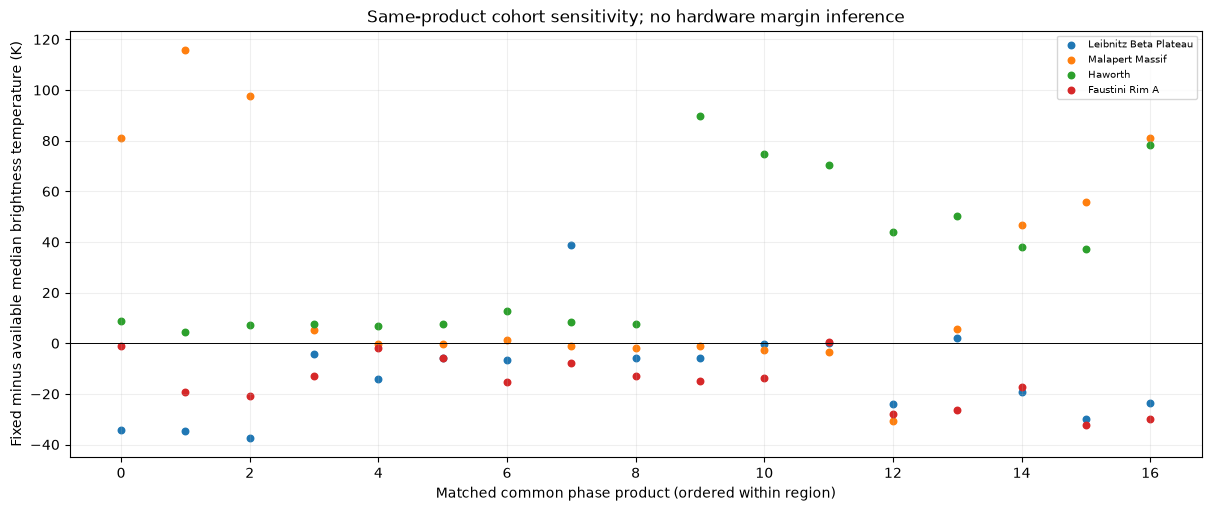

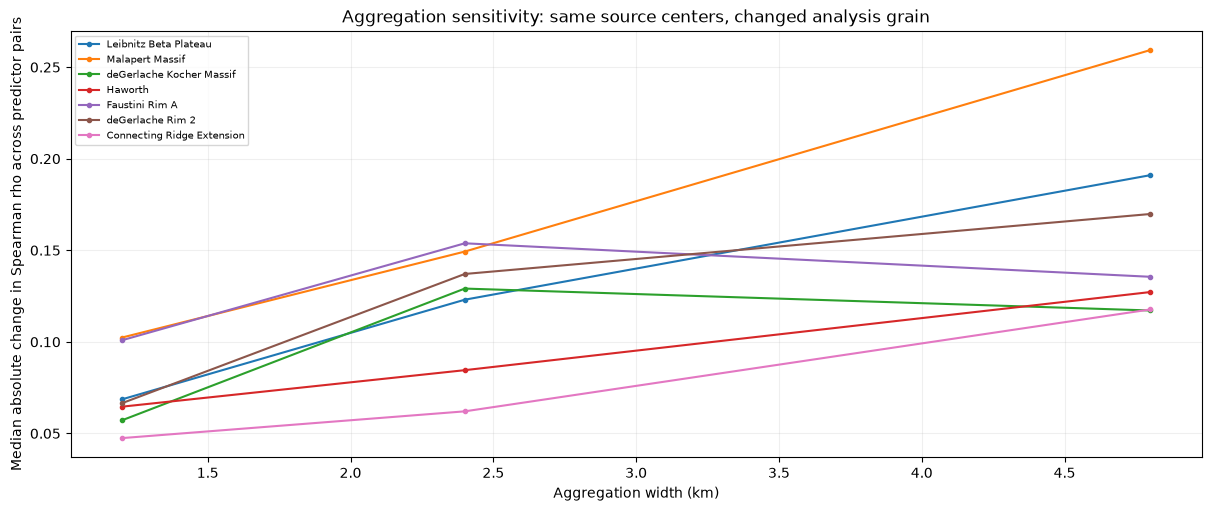

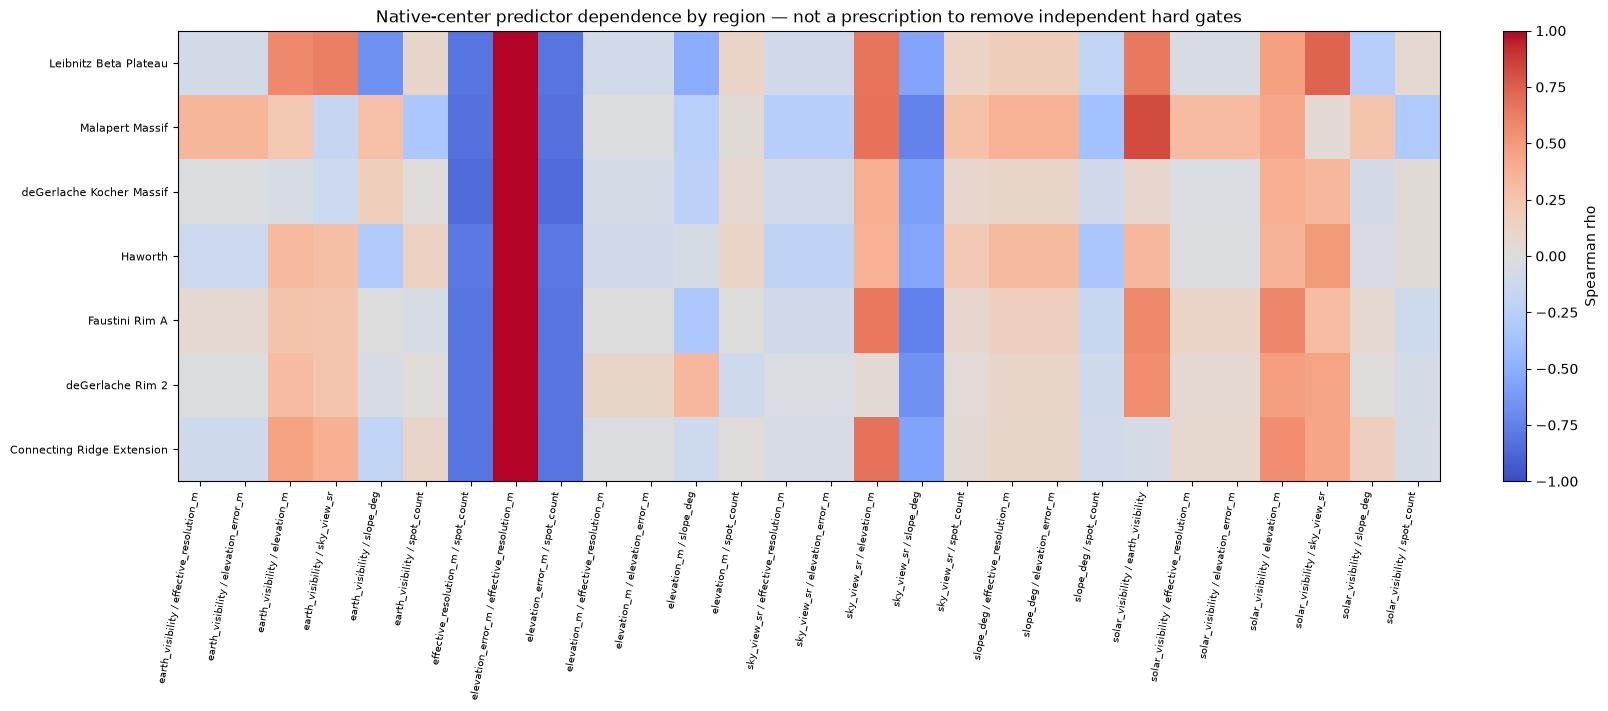

{'regions': 7,
 'matched_product_cohort_comparisons': 68,
 'largest_absolute_cohort_median_shift_K': 115.78749099999999,
 'largest_cohort_shift_example': {'region': 'A3CLR22_11_Malapert_Massif',
  'source_product': 'pcp_avg_tbol_pols_ls030_slon02_240',
  'usable_rows': 7569,
  'fixed_common_rows': 6051,
  'fixed_minus_available_median_K': 115.78749099999999},
 'native_predictor_pairs': 196,
 'scale_comparisons': 588,
 'largest_absolute_aggregation_rho_change': 0.659271363591306,
 'largest_scale_change_example': {'region': 'A3CLR22_12_deGerlache_Kocher_Massif',
  'variable_a': 'elevation_m',
  'variable_b': 'spot_count',
  'aggregation_width_m': 4800,
  'native_spearman_rho': 0.06471403160534159,
  'spearman_rho': 0.7239853951966476,
  'pairs': 25},
 'descriptive_sign_reversals': 22,
 'quality_band_comparisons': 12218,
 'quality_band_comparable_rows': 12160,
 'mission_ranking_computed': False,
 'limits': ['No independence assumed for repeated/neighboring centers',
  'Different data grai

,region,variable_a,variable_b,native_spearman_rho
53,A3CLR22_11_Malapert_Massif,elevation_error_m,effective_resolution_m,1.000000
25,A3CLR22_10_Leibnitz_Beta_Plateau,elevation_error_m,effective_resolution_m,1.000000
137,A3CLR22_3_Faustini_Rim_A,elevation_error_m,effective_resolution_m,1.000000
81,A3CLR22_12_deGerlache_Kocher_Massif,elevation_error_m,effective_resolution_m,1.000000
193,A3CLR22_5_Connecting_Ridge_Extension,elevation_error_m,effective_resolution_m,1.000000
109,A3CLR22_2_Haworth,elevation_error_m,effective_resolution_m,1.000000
165,A3CLR22_4_deGerlache_Rim_2,elevation_error_m,effective_resolution_m,1.000000
83,A3CLR22_12_deGerlache_Kocher_Massif,effective_resolution_m,spot_count,-0.856371
82,A3CLR22_12_deGerlache_Kocher_Massif,elevation_error_m,spot_count,-0.856371
28,A3CLR22_11_Malapert_Massif,solar_visibility,earth_visibility,0.825363


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_013_feature_sensitivity\20261109T142659492170Z_b205c5


In [2]:
JOINT_RUN_ID=None
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
joint_prov=json.loads((joint/'provenance.json').read_text())
environment=(ROOT/joint_prov['config']['environment_run']).resolve()
quality_run=latest_completed_run(ROOT,'analysis/dar_006_research_terrain')
quality_prov=json.loads((quality_run/'provenance.json').read_text())
source_key=str((environment/'provenance.json').relative_to(ROOT))
if source_key not in quality_prov['inputs']:raise ValueError('Quality studies used a different environmental source run')
with Run(ROOT,'analysis/dar_013_feature_sensitivity',{'joint_run':str(joint.relative_to(ROOT)),
    'quality_run':str(quality_run.relative_to(ROOT)),'aggregation_widths_m':[0,1200,2400,4800],
    'scope':'descriptive sensitivities only; no candidate ranking or automatic rule changes'},'Moon/Environmental_Context/Dar_013_feature_sensitivity_redundancy.ipynb') as run:
    run.input(Path(decision_eda.__file__))
    centers=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'))
    regional=pd.read_csv(accepted_input(run,joint,'region_phase_features.csv'))
    regions=sorted(centers.region.unique())
    matched=regional.loc[regional.common_product & regional.fixed_common_rows.gt(0)&regional.usable_rows.gt(0)].copy()
    matched['fixed_minus_available_median_K']=matched.fixed_common_tbol_median_K-matched.tbol_median_K
    matched['fixed_fraction_of_available_centers']=matched.fixed_common_rows/matched.usable_rows
    matched.to_csv(run.path('matched_product_cohort_sensitivity.csv'),index=False)
    matched.groupby('region').fixed_minus_available_median_K.agg(['count','min','median','max']).to_csv(run.path('cohort_sensitivity_by_region.csv'))
    fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
    for region,part in matched.groupby('region'):
        ax.scatter(np.arange(len(part)),part.fixed_minus_available_median_K,label=short(region),s=22)
    ax.axhline(0,color='black',lw=.7);ax.set(xlabel='Matched common phase product (ordered within region)',
        ylabel='Fixed minus available median brightness temperature (K)',title='Same-product cohort sensitivity; no hardware margin inference')
    ax.legend(fontsize=7);ax.grid(alpha=.2);savefig(run,fig,'matched_cohort_sensitivity')
    correlations=[]
    for width in [0,1200,2400,4800]:
        if width==0:grouped=centers
        else:
            grouped=assign_blocks(centers,width).groupby(BLOCK_KEYS,observed=True)[PREDICTORS].mean().reset_index()
        part=pairwise_spearman(grouped,PREDICTORS,['region']);part['aggregation_width_m']=width
        correlations.append(part)
    correlations=pd.concat(correlations,ignore_index=True)
    correlations.to_csv(run.path('predictor_correlations_by_scale.csv'),index=False)
    native=correlations.loc[correlations.aggregation_width_m.eq(0)].rename(columns={'spearman_rho':'native_spearman_rho','pairs':'native_pairs'})
    scales=correlations.loc[correlations.aggregation_width_m.gt(0)].merge(
        native[['region','variable_a','variable_b','native_spearman_rho','native_pairs']],on=['region','variable_a','variable_b'],validate='many_to_one')
    scales['delta_rho_from_native']=scales.spearman_rho-scales.native_spearman_rho
    scales['rho_sign_reversal']=scales.spearman_rho*scales.native_spearman_rho<0
    scales.to_csv(run.path('aggregation_sensitivity.csv'),index=False)
    fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
    for region,part in scales.groupby('region'):
        grouped=part.groupby('aggregation_width_m').delta_rho_from_native.apply(lambda v:v.abs().median())
        ax.plot(grouped.index/1000,grouped,marker='.',label=short(region))
    ax.set(xlabel='Aggregation width (km)',ylabel='Median absolute change in Spearman rho across predictor pairs',
        title='Aggregation sensitivity: same source centers, changed analysis grain')
    ax.legend(fontsize=7);ax.grid(alpha=.2);savefig(run,fig,'aggregation_sensitivity')
    native['pair']=native.variable_a+' / '+native.variable_b
    display_matrix=native.pivot(index='region',columns='pair',values='native_spearman_rho')
    fig,ax=plt.subplots(figsize=(16,7),layout='constrained')
    im=ax.imshow(display_matrix,aspect='auto',vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_yticks(range(len(display_matrix)),[short(x) for x in display_matrix.index],fontsize=8)
    ax.set_xticks(range(len(display_matrix.columns)),display_matrix.columns,rotation=80,ha='right',fontsize=7)
    ax.set_title('Native-center predictor dependence by region — not a prescription to remove independent hard gates')
    fig.colorbar(im,ax=ax,label='Spearman rho');savefig(run,fig,'predictor_redundancy_context')
    baseline=pd.read_csv(accepted_input(run,environment,'within_product_correlations.csv'))
    baseline=baseline.loc[baseline.cohort.eq('available')]
    quality=pd.read_csv(accepted_input(run,quality_run,'within_product_quality_band_correlations.csv'))
    quality=quality.loc[quality.region.isin(regions)]
    long=[]
    for predictor in ['solar_visibility','slope_deg']:
        part=quality[['region','source_product','quality_layer','quality_band','rho_'+predictor,'pairs_'+predictor]].rename(
            columns={'rho_'+predictor:'quality_band_rho','pairs_'+predictor:'quality_band_pairs'})
        base=baseline.loc[baseline.variable.eq(predictor),['region','source_product','spearman_rho','paired_rows']].rename(
            columns={'spearman_rho':'all_center_rho','paired_rows':'all_center_pairs'})
        part=part.merge(base,on=['region','source_product'],how='left',validate='many_to_one')
        part['predictor']=predictor;part['delta_rho']=part.quality_band_rho-part.all_center_rho
        part['comparison_status']=np.where(part.delta_rho.notna(),'descriptive','undefined_for_one_cohort')
        long.append(part)
    quality_comparison=pd.concat(long,ignore_index=True)
    quality_comparison.to_csv(run.path('matched_quality_band_sensitivity.csv'),index=False)
    quality_comparison.groupby(['region','quality_layer','quality_band','predictor']).delta_rho.agg(['count','median','min','max']).to_csv(run.path('quality_band_sensitivity_summary.csv'))
    valid_native=native.loc[native.native_spearman_rho.notna()].copy();valid_native['absolute_rho']=valid_native.native_spearman_rho.abs()
    strongest=valid_native.sort_values('absolute_rho',ascending=False).head(12)
    strongest[['region','variable_a','variable_b','native_pairs','native_spearman_rho']].to_csv(run.path('strongest_context_dependencies.csv'),index=False)
    max_cohort=matched.loc[matched.fixed_minus_available_median_K.abs().idxmax()] if len(matched) else None
    max_scale=scales.loc[scales.delta_rho_from_native.abs().idxmax()] if scales.delta_rho_from_native.notna().any() else None
    findings(run,{'regions':len(regions),'matched_product_cohort_comparisons':len(matched),
        'largest_absolute_cohort_median_shift_K':float(matched.fixed_minus_available_median_K.abs().max()) if len(matched) else None,
        'largest_cohort_shift_example':None if max_cohort is None else max_cohort[['region','source_product','usable_rows','fixed_common_rows','fixed_minus_available_median_K']].to_dict(),
        'native_predictor_pairs':len(native),'scale_comparisons':len(scales),
        'largest_absolute_aggregation_rho_change':float(scales.delta_rho_from_native.abs().max()),
        'largest_scale_change_example':None if max_scale is None else max_scale[['region','variable_a','variable_b','aggregation_width_m','native_spearman_rho','spearman_rho','pairs']].to_dict(),
        'descriptive_sign_reversals':int(scales.rho_sign_reversal.sum()),'quality_band_comparisons':len(quality_comparison),
        'quality_band_comparable_rows':int(quality_comparison.delta_rho.notna().sum()),
        'mission_ranking_computed':False,'limits':['No independence assumed for repeated/neighboring centers',
            'Different data grains change associations; this is not a causal estimate','No automatic weighting or hard-rule removal']})
    display(strongest[['region','variable_a','variable_b','native_spearman_rho']])
OUT=run.directory;print('Completed:',OUT)

## Algorithm handoff
Keep source grain, quality and cohort flags with each candidate/phase feature. Test future
scoring choices against these sensitivities once a mission profile and eligible cohort
exist. Correlated inputs may double-count a soft preference, but two correlated physical
quantities can still support separate mandatory requirements: do not remove a hard rule
based on correlation. Keep terrain penalties attributable to their own assessment stage.